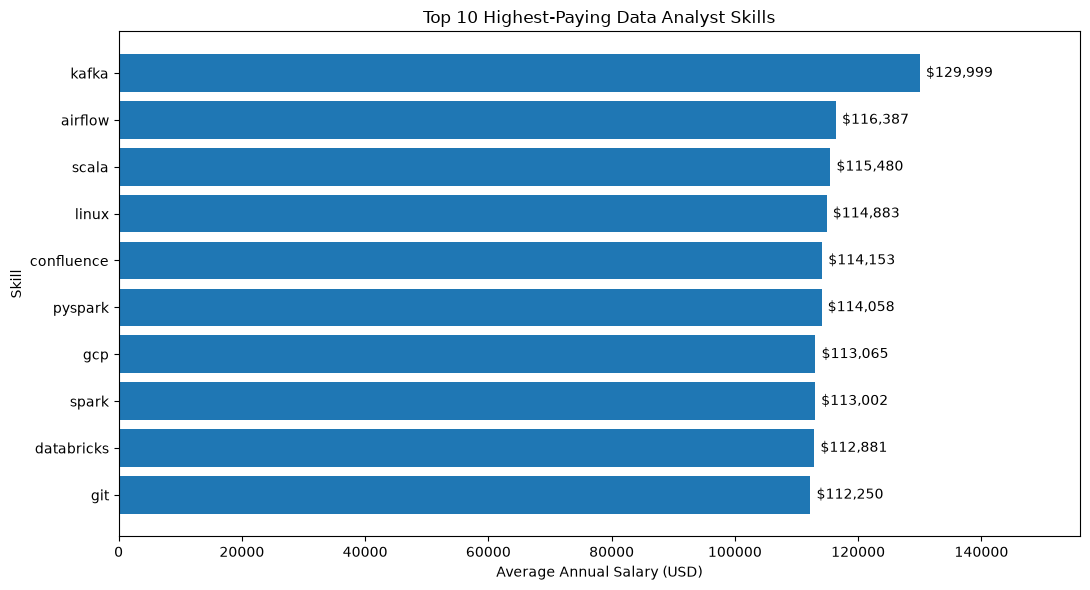

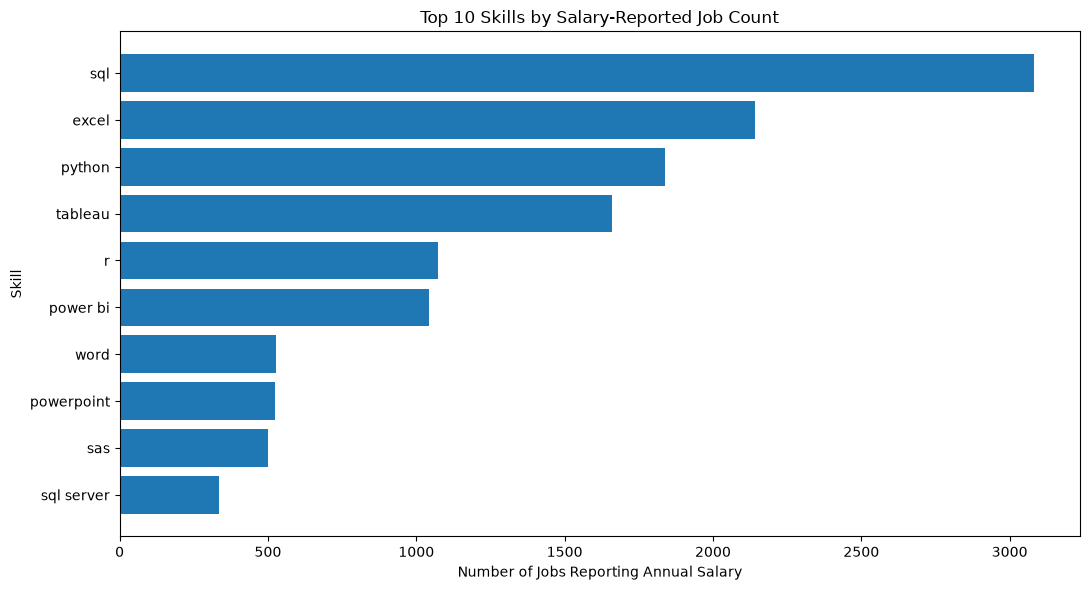

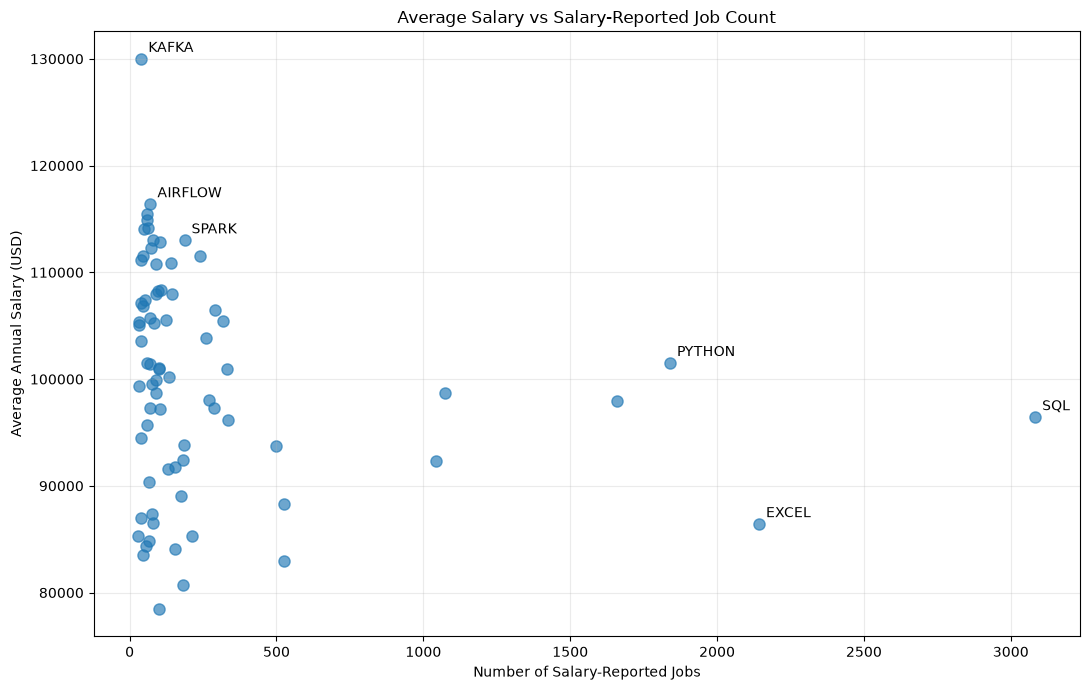

Skills analyzed: 74
Median of skill averages: 100573.32

Top 10 by salary:
    skills  salary_job_count  avg_salary
     kafka                40   129999.16
   airflow                71   116387.26
     scala                59   115479.53
     linux                58   114883.20
confluence                62   114153.12
   pyspark                49   114057.87
       gcp                78   113065.48
     spark               187   113001.94
databricks               102   112880.74
       git                74   112249.64


In [4]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("C:/Users/Admin/Desktop/SQL_Projects/project_sql/4_top_paying_skill.csv")

# Clean the data
df["skills"] = df["skills"].str.strip().str.lower()
df["salary_job_count"] = pd.to_numeric(
    df["salary_job_count"], errors="coerce"
)
df["avg_salary"] = pd.to_numeric(
    df["avg_salary"], errors="coerce"
)
df = df.dropna(subset=["skills", "salary_job_count", "avg_salary"])

# CHART 1: Top 10 highest-paying skills
top_salary = df.nlargest(10, "avg_salary").sort_values("avg_salary")

plt.figure(figsize=(11, 6))
plt.barh(top_salary["skills"], top_salary["avg_salary"])

plt.title("Top 10 Highest-Paying Data Analyst Skills")
plt.xlabel("Average Annual Salary (USD)")
plt.ylabel("Skill")
plt.xlim(0, top_salary["avg_salary"].max() * 1.2)

for i, salary in enumerate(top_salary["avg_salary"]):
    plt.text(salary + 1000, i, f"${salary:,.0f}", va="center")

plt.tight_layout()
plt.show()


# CHART 2: Skills with most salary-reported jobs
top_count = df.nlargest(10, "salary_job_count")
top_count = top_count.sort_values("salary_job_count")

plt.figure(figsize=(11, 6))
plt.barh(top_count["skills"], top_count["salary_job_count"])

plt.title("Top 10 Skills by Salary-Reported Job Count")
plt.xlabel("Number of Jobs Reporting Annual Salary")
plt.ylabel("Skill")

plt.tight_layout()
plt.show()


# CHART 3: Salary vs salary-reported job count
plt.figure(figsize=(11, 7))

plt.scatter(
    df["salary_job_count"],
    df["avg_salary"],
    alpha=0.65,
    s=65
)

highlight = ["sql", "python", "excel", "kafka", "airflow", "spark"]

for _, row in df[df["skills"].isin(highlight)].iterrows():
    plt.annotate(
        row["skills"].upper(),
        (row["salary_job_count"], row["avg_salary"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Average Salary vs Salary-Reported Job Count")
plt.xlabel("Number of Salary-Reported Jobs")
plt.ylabel("Average Annual Salary (USD)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# Summary
print("Skills analyzed:", len(df))
print("Median of skill averages:", round(df["avg_salary"].median(), 2))
print("\nTop 10 by salary:")
print(df.nlargest(10, "avg_salary").to_string(index=False))
